In [8]:

import os


print("Current working directory:")
print(os.getcwd())

# Dataset folders
print("\nFiles and folders in current directory:")
print(os.listdir("."))

print("\nChecking dataset folders:")

for folder in ["kaggle_3m", "lgg-mri-segmentation"]:
    print(f"{folder}: {os.path.exists(folder)}")


Current working directory:
c:\Micro-project

Files and folders in current directory:
['.git', '.gitignore', 'archive (2)', 'computervision (1).ipynb', 'dataset_splits', 'project.ipynb']

Checking dataset folders:
kaggle_3m: False
lgg-mri-segmentation: False


In [9]:

import os

base_path = os.path.join(os.getcwd(), "archive (2)")

dataset_path = os.path.join(base_path, "lgg-mri-segmentation")
data_path = os.path.join(dataset_path, "kaggle_3m")

print("Base folder exists:", os.path.exists(base_path))
print("Dataset folder exists:", os.path.exists(dataset_path))
print("MRI data folder exists:", os.path.exists(data_path))

if os.path.exists(dataset_path):
    print("\nDataset contents:")
    print(os.listdir(dataset_path))

if os.path.exists(data_path):
    patient_folders = [
        folder for folder in os.listdir(data_path)
        if os.path.isdir(os.path.join(data_path, folder))
    ]

    print("\nTotal patient folders:", len(patient_folders))
    print("First 5 folders:", patient_folders[:5])


Base folder exists: True
Dataset folder exists: True
MRI data folder exists: True

Dataset contents:
['kaggle_3m']

Total patient folders: 110
First 5 folders: ['TCGA_CS_4941_19960909', 'TCGA_CS_4942_19970222', 'TCGA_CS_4943_20000902', 'TCGA_CS_4944_20010208', 'TCGA_CS_5393_19990606']


In [10]:

import os

image_count = 0
mask_count = 0
other_files = 0

for patient in os.listdir(data_path):
    patient_path = os.path.join(data_path, patient)

    if not os.path.isdir(patient_path):
        continue

    for file in os.listdir(patient_path):
        if not file.lower().endswith(".tif"):
            other_files += 1
            continue

        if "mask" in file.lower():
            mask_count += 1
        else:
            image_count += 1

print("Total MRI images:", image_count)
print("Total tumor masks:", mask_count)
print("Other files:", other_files)


Total MRI images: 3929
Total tumor masks: 3929
Other files: 0


Patient: TCGA_CS_4941_19960909
MRI file: TCGA_CS_4941_19960909_1.tif
Mask file: TCGA_CS_4941_19960909_1_mask.tif
MRI shape: (256, 256)
Mask shape: (256, 256)
Mask pixel values: [0]


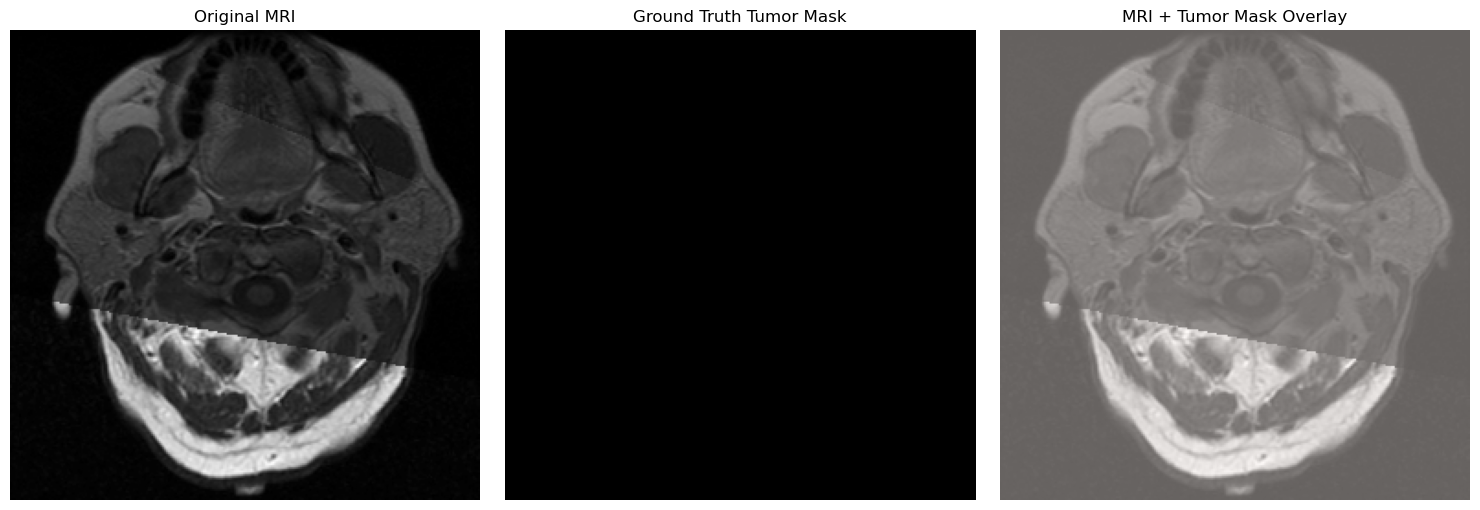

In [11]:

import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Find one MRI image and its corresponding mask
sample_image = None
sample_mask = None

for patient in os.listdir(data_path):
    patient_path = os.path.join(data_path, patient)

    if not os.path.isdir(patient_path):
        continue

    for file in os.listdir(patient_path):
        if file.lower().endswith(".tif") and "mask" not in file.lower():

            image_path = os.path.join(patient_path, file)
            mask_name = file[:-4] + "_mask.tif"
            mask_path = os.path.join(patient_path, mask_name)

            if os.path.exists(mask_path):
                sample_image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
                sample_mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

                print("Patient:", patient)
                print("MRI file:", file)
                print("Mask file:", mask_name)
                break

    if sample_image is not None:
        break

if sample_image is not None and sample_mask is not None:

    print("MRI shape:", sample_image.shape)
    print("Mask shape:", sample_mask.shape)
    print("Mask pixel values:", np.unique(sample_mask))

    plt.figure(figsize=(15, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(sample_image, cmap="gray")
    plt.title("Original MRI")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(sample_mask, cmap="gray")
    plt.title("Ground Truth Tumor Mask")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(sample_image, cmap="gray")
    plt.imshow(sample_mask, cmap="Reds", alpha=0.4)
    plt.title("MRI + Tumor Mask Overlay")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

else:
    print("No matching MRI-mask pair found. Check the filenames.")


In [12]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

total_images = 0
matched_pairs = 0
missing_masks = []
empty_masks = []
positive_masks = []
dimension_mismatches = []

data_path = os.path.abspath(data_path)

for patient in sorted(os.listdir(data_path)):
    patient_path = os.path.join(data_path, patient)

    if not os.path.isdir(patient_path):
        continue

    for filename in sorted(os.listdir(patient_path)):

        if not filename.lower().endswith(".tif"):
            continue

        if "mask" in filename.lower():
            continue

        total_images += 1

        image_path = os.path.join(patient_path, filename)
        mask_name = filename[:-4] + "_mask.tif"
        mask_path = os.path.join(patient_path, mask_name)

        if not os.path.exists(mask_path):
            missing_masks.append((patient, filename))
            continue

        image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

        if image is None or mask is None:
            continue

        matched_pairs += 1

        if image.shape != mask.shape:
            dimension_mismatches.append(
                (filename, image.shape, mask.shape)
            )
            continue

        tumor_pixels = int(np.count_nonzero(mask))

        if tumor_pixels > 0:
            positive_masks.append(
                (image_path, mask_path, filename, tumor_pixels)
            )
        else:
            empty_masks.append(filename)

print("========== DATASET VALIDATION ==========")
print("Total MRI images:", total_images)
print("Matched image-mask pairs:", matched_pairs)
print("Missing masks:", len(missing_masks))
print("Dimension mismatches:", len(dimension_mismatches))
print("Masks containing tumor pixels:", len(positive_masks))
print("Empty masks:", len(empty_masks))

if total_images:
    print(
        "Pairing coverage:",
        round(100 * matched_pairs / total_images, 2),
        "%"
    )

if positive_masks:
    print("\nExample tumor-positive image:")
    print(positive_masks[0][2])

========== DATASET VALIDATION ==========
Total MRI images: 3929
Matched image-mask pairs: 3929
Missing masks: 0
Dimension mismatches: 0
Masks containing tumor pixels: 1373
Empty masks: 2556
Pairing coverage: 100.0 %

Example tumor-positive image:
TCGA_CS_4941_19960909_11.tif


MRI: TCGA_CS_4941_19960909_11.tif
MRI dimensions: (256, 256)
Mask dimensions: (256, 256)
Tumor pixels: 1426


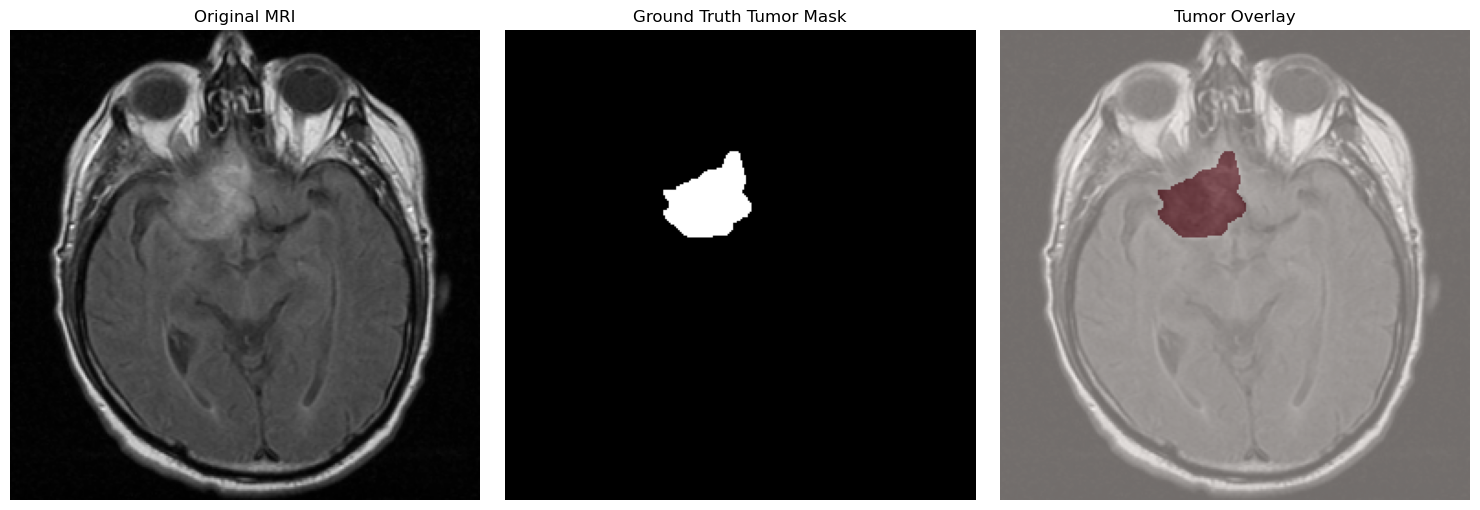

In [13]:
if positive_masks:

    image_path, mask_path, filename, tumor_pixels = positive_masks[0]

    image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

    print("MRI:", filename)
    print("MRI dimensions:", image.shape)
    print("Mask dimensions:", mask.shape)
    print("Tumor pixels:", tumor_pixels)

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    axes[0].imshow(image, cmap="gray")
    axes[0].set_title("Original MRI")

    axes[1].imshow(mask, cmap="gray")
    axes[1].set_title("Ground Truth Tumor Mask")

    axes[2].imshow(image, cmap="gray")
    axes[2].imshow(mask > 0, cmap="Reds", alpha=0.45)
    axes[2].set_title("Tumor Overlay")

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

else:
    print("No tumor-positive masks found. Check mask loading and pixel values.")

In [14]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

# Dataset path
DATASET_PATH = Path(r"C:\Micro-project\archive (2)\kaggle_3m")

print("Dataset path:", DATASET_PATH)
print("Dataset exists:", DATASET_PATH.exists())

if not DATASET_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATASET_PATH}"
    )

patient_folders = [
    folder for folder in DATASET_PATH.iterdir()
    if folder.is_dir()
]

print("Total patient folders:", len(patient_folders))
print("First 5 folders:", [p.name for p in patient_folders[:5]])

Dataset path: C:\Micro-project\archive (2)\kaggle_3m
Dataset exists: True
Total patient folders: 110
First 5 folders: ['TCGA_CS_4941_19960909', 'TCGA_CS_4942_19970222', 'TCGA_CS_4943_20000902', 'TCGA_CS_4944_20010208', 'TCGA_CS_5393_19990606']


In [15]:
records = []
missing_masks = []

for patient_folder in sorted(DATASET_PATH.iterdir()):

    if not patient_folder.is_dir():
        continue

    for image_path in sorted(patient_folder.glob("*.tif")):

        # Mask files ko MRI images na samjhein
        if "_mask" in image_path.stem.lower():
            continue

        # Corresponding mask filename
        mask_path = image_path.with_name(
            image_path.stem + "_mask.tif"
        )

        if not mask_path.exists():
            missing_masks.append(str(image_path))
            continue

        records.append({
            "patient_id": patient_folder.name,
            "image_path": str(image_path),
            "mask_path": str(mask_path),
            "image_name": image_path.name
        })

df = pd.DataFrame(records)

print("Total matched MRI-mask pairs:", len(df))
print("Missing masks:", len(missing_masks))
print("Unique patients:", df["patient_id"].nunique())

if missing_masks:
    print("\nFirst missing-mask examples:")
    print(missing_masks[:5])

if df.empty:
    raise ValueError("No MRI-mask pairs found. Check dataset paths.")

assert df["image_path"].is_unique
assert df["mask_path"].is_unique

Total matched MRI-mask pairs: 3929
Missing masks: 0
Unique patients: 110


In [16]:
from sklearn.model_selection import GroupShuffleSplit

# First: 15% patients/slices ko final test set mein rakho
split_1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.15,
    random_state=42
)

train_val_idx, test_idx = next(
    split_1.split(df, groups=df["patient_id"])
)

train_val_df = df.iloc[train_val_idx].reset_index(drop=True)
test_df = df.iloc[test_idx].reset_index(drop=True)

# Second: Remaining data se overall ~15% validation set
# 0.15 / 0.85 = 0.17647
split_2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.15 / 0.85,
    random_state=42
)

train_idx, val_idx = next(
    split_2.split(
        train_val_df,
        groups=train_val_df["patient_id"]
    )
)

train_df = train_val_df.iloc[train_idx].reset_index(drop=True)
val_df = train_val_df.iloc[val_idx].reset_index(drop=True)

# Check for patient overlap
train_patients = set(train_df["patient_id"])
val_patients = set(val_df["patient_id"])
test_patients = set(test_df["patient_id"])

assert train_patients.isdisjoint(val_patients)
assert train_patients.isdisjoint(test_patients)
assert val_patients.isdisjoint(test_patients)

print("TRAINING")
print("MRI slices:", len(train_df))
print("Patients:", train_df["patient_id"].nunique())

print("\nVALIDATION")
print("MRI slices:", len(val_df))
print("Patients:", val_df["patient_id"].nunique())

print("\nTEST")
print("MRI slices:", len(test_df))
print("Patients:", test_df["patient_id"].nunique())

print("\nTOTAL:", len(train_df) + len(val_df) + len(test_df))
print("Patient overlap: None")

TRAINING
MRI slices: 2795
Patients: 76

VALIDATION
MRI slices: 601
Patients: 17

TEST
MRI slices: 533
Patients: 17

TOTAL: 3929
Patient overlap: None


In [17]:
SPLIT_DIR = Path(r"C:\Micro-project\dataset_splits")
SPLIT_DIR.mkdir(parents=True, exist_ok=True)

train_df.to_csv(SPLIT_DIR / "train.csv", index=False)
val_df.to_csv(SPLIT_DIR / "validation.csv", index=False)
test_df.to_csv(SPLIT_DIR / "test.csv", index=False)

print("Split files saved successfully!")
print("Location:", SPLIT_DIR)

print("\nFiles:")
for file in SPLIT_DIR.iterdir():
    print(file.name)

Split files saved successfully!
Location: C:\Micro-project\dataset_splits

Files:
test.csv
train.csv
validation.csv


In [18]:
def preprocess_image(image_path):
    """
    Read MRI image and normalize it to [0, 1].
    """
    image = cv2.imread(
        str(image_path),
        cv2.IMREAD_GRAYSCALE
    )

    if image is None:
        raise ValueError(f"Could not read MRI: {image_path}")

    image = image.astype(np.float32)

    # Per-image min-max normalization
    min_val = image.min()
    max_val = image.max()

    if max_val > min_val:
        image = (image - min_val) / (max_val - min_val)
    else:
        image = np.zeros_like(image, dtype=np.float32)

    return image


def preprocess_mask(mask_path):
    """
    Read ground-truth mask and convert it to binary values.
    """
    mask = cv2.imread(
        str(mask_path),
        cv2.IMREAD_GRAYSCALE
    )

    if mask is None:
        raise ValueError(f"Could not read mask: {mask_path}")

    # Tumor pixels = 1; background pixels = 0
    mask = (mask > 0).astype(np.float32)

    return mask

In [19]:
import torch
from torch.utils.data import Dataset, DataLoader


class BrainTumorDataset(Dataset):

    def __init__(self, dataframe):
        self.dataframe = dataframe.reset_index(drop=True)

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):

        row = self.dataframe.iloc[idx]

        image = preprocess_image(row["image_path"])
        mask = preprocess_mask(row["mask_path"])

        # Check image-mask alignment
        if image.shape != mask.shape:
            raise ValueError(
                f"Dimension mismatch: "
                f"{image.shape} vs {mask.shape}"
            )

        # Add channel dimension: H x W -> 1 x H x W
        image = torch.from_numpy(image).unsqueeze(0)
        mask = torch.from_numpy(mask).unsqueeze(0)

        return image, mask

In [20]:
train_dataset = BrainTumorDataset(train_df)
val_dataset = BrainTumorDataset(val_df)
test_dataset = BrainTumorDataset(test_df)

BATCH_SIZE = 8

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Training batches: 350
Validation batches: 76
Test batches: 67


In [21]:
images, masks = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Mask batch shape:", masks.shape)

print("Image minimum:", images.min().item())
print("Image maximum:", images.max().item())

print("Mask unique values:", torch.unique(masks))

Image batch shape: torch.Size([8, 1, 256, 256])
Mask batch shape: torch.Size([8, 1, 256, 256])
Image minimum: 0.0
Image maximum: 1.0
Mask unique values: tensor([0., 1.])


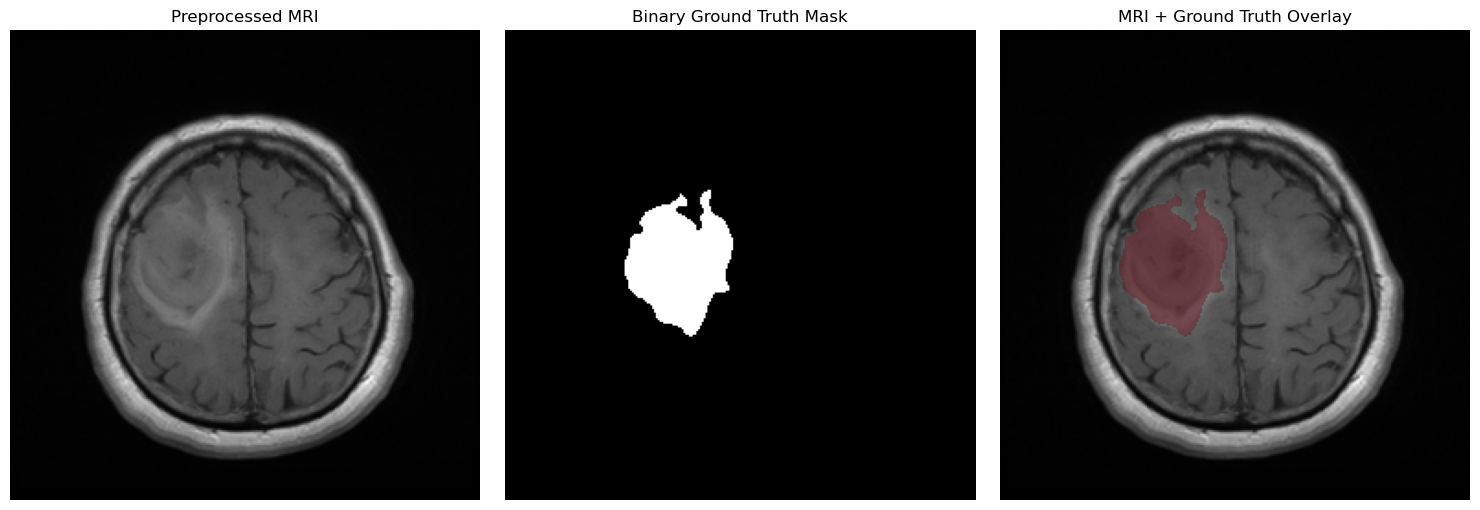

In [22]:
image = images[0, 0].numpy()
mask = masks[0, 0].numpy()

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(image, cmap="gray", vmin=0, vmax=1)
plt.title("Preprocessed MRI")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(mask, cmap="gray", vmin=0, vmax=1)
plt.title("Binary Ground Truth Mask")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(image, cmap="gray", vmin=0, vmax=1)
plt.imshow(
    np.ma.masked_where(mask == 0, mask),
    cmap="Reds",
    alpha=0.4,
    vmin=0,
    vmax=1
)
plt.title("MRI + Ground Truth Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

In [23]:
import random
import cv2
import numpy as np

def augment_pair(image, mask):

    h, w = image.shape

    # Random rotation and scaling
    angle = random.uniform(-10, 10)
    scale = random.uniform(0.9, 1.1)

    # Random translation
    tx = random.uniform(-0.05, 0.05) * w
    ty = random.uniform(-0.05, 0.05) * h

    # Create transformation matrix
    matrix = cv2.getRotationMatrix2D(
        (w / 2, h / 2),
        angle,
        scale
    )

    matrix[0, 2] += tx
    matrix[1, 2] += ty

    # Apply same transformation to MRI
    image = cv2.warpAffine(
        image,
        matrix,
        (w, h),
        flags=cv2.INTER_LINEAR,
        borderMode=cv2.BORDER_CONSTANT,
        borderValue=0
    )

    # Apply same transformation to mask
    mask = cv2.warpAffine(
        mask,
        matrix,
        (w, h),
        flags=cv2.INTER_NEAREST,
        borderMode=cv2.BORDER_CONSTANT,
        borderValue=0
    )

    # Slight brightness and contrast variation
    if random.random() < 0.5:

        alpha = random.uniform(0.9, 1.1)
        beta = random.uniform(-0.05, 0.05)

        image = alpha * image + beta
        image = np.clip(image, 0, 1)

    # Ensure binary mask
    mask = (mask > 0.5).astype(np.float32)

    return image.astype(np.float32), mask

In [24]:
import torch
from torch.utils.data import Dataset, DataLoader

class BrainTumorDataset(Dataset):

    def __init__(self, dataframe, augment=False):
        self.dataframe = dataframe.reset_index(drop=True)
        self.augment = augment

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):

        row = self.dataframe.iloc[idx]

        # Load and preprocess MRI and mask
        image = preprocess_image(row["image_path"])
        mask = preprocess_mask(row["mask_path"])

        # Apply augmentation only when enabled
        if self.augment:
            image, mask = augment_pair(image, mask)

        # Convert to PyTorch tensors
        image = torch.from_numpy(image).unsqueeze(0)
        mask = torch.from_numpy(mask).unsqueeze(0)

        return image, mask

In [25]:
# Reproducibility
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

# Training dataset: augmentation ON
train_dataset = BrainTumorDataset(
    train_df,
    augment=True
)

# Validation dataset: augmentation OFF
val_dataset = BrainTumorDataset(
    val_df,
    augment=False
)

# Test dataset: augmentation OFF
test_dataset = BrainTumorDataset(
    test_df,
    augment=False
)

BATCH_SIZE = 8

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

print("\nAugmentation enabled:", train_dataset.augment)
print("Validation augmentation:", val_dataset.augment)
print("Test augmentation:", test_dataset.augment)

Training batches: 350
Validation batches: 76
Testing batches: 67

Augmentation enabled: True
Validation augmentation: False
Test augmentation: False


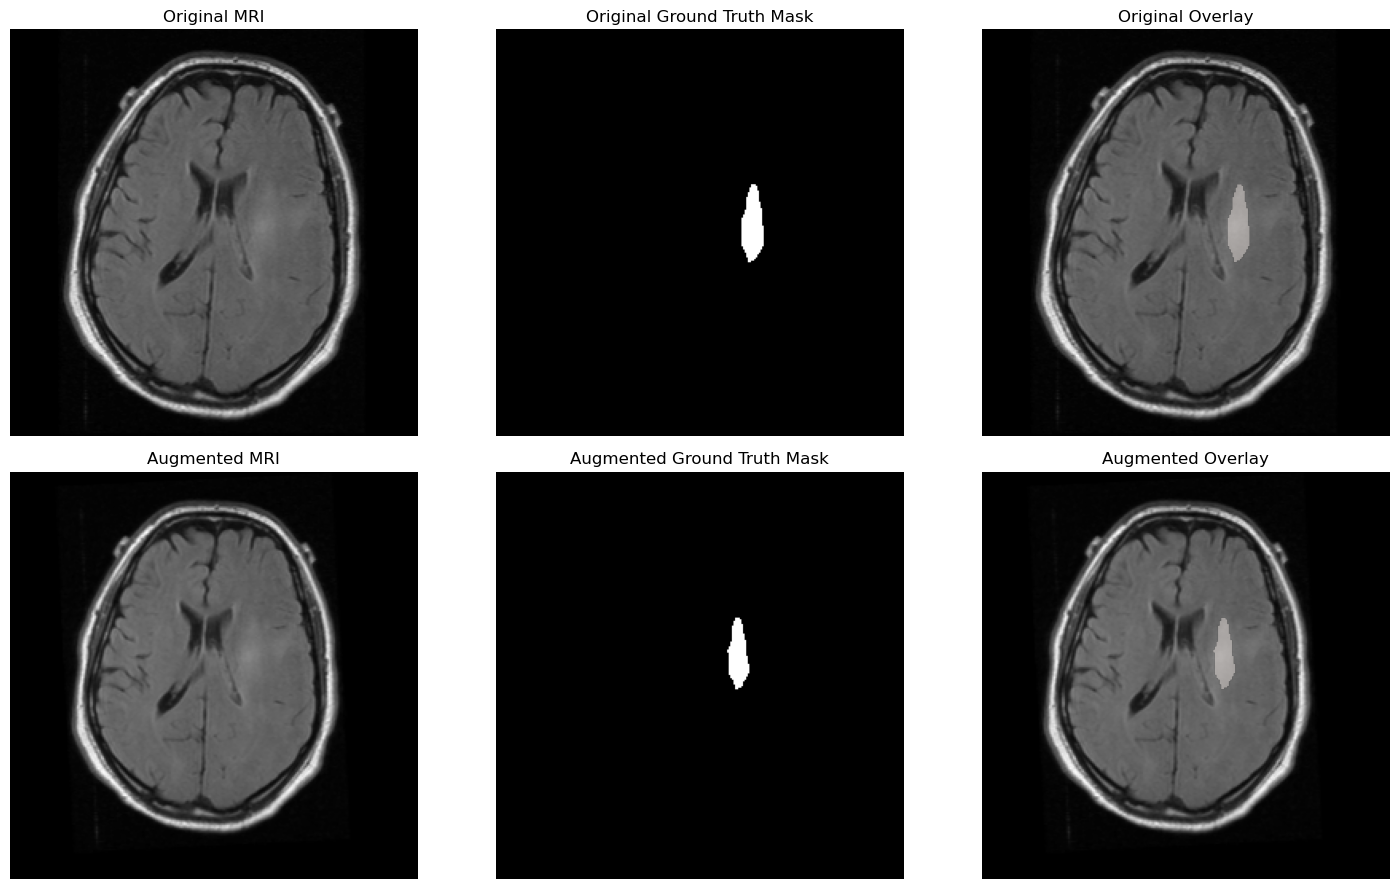

Original mask values: [0. 1.]
Augmented mask values: [0. 1.]
Original tumor pixels: 495
Augmented tumor pixels: 407


In [26]:
# Find a tumor-positive training sample
sample_idx = None

for idx in range(len(train_df)):
    sample_mask = preprocess_mask(
        train_df.iloc[idx]["mask_path"]
    )

    if np.any(sample_mask > 0):
        sample_idx = idx
        break

if sample_idx is None:
    raise ValueError("No tumor-positive training sample found.")

# Load original image and mask
row = train_df.iloc[sample_idx]

original_image = preprocess_image(row["image_path"])
original_mask = preprocess_mask(row["mask_path"])

# Generate augmented sample
aug_image, aug_mask = augment_pair(
    original_image.copy(),
    original_mask.copy()
)

# Visual comparison
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

# Original MRI
axes[0, 0].imshow(original_image, cmap="gray")
axes[0, 0].set_title("Original MRI")

# Original mask
axes[0, 1].imshow(original_mask, cmap="gray")
axes[0, 1].set_title("Original Ground Truth Mask")

# Original overlay
axes[0, 2].imshow(original_image, cmap="gray")
axes[0, 2].imshow(
    np.ma.masked_where(original_mask == 0, original_mask),
    cmap="Reds",
    alpha=0.4
)
axes[0, 2].set_title("Original Overlay")

# Augmented MRI
axes[1, 0].imshow(aug_image, cmap="gray")
axes[1, 0].set_title("Augmented MRI")

# Augmented mask
axes[1, 1].imshow(aug_mask, cmap="gray")
axes[1, 1].set_title("Augmented Ground Truth Mask")

# Augmented overlay
axes[1, 2].imshow(aug_image, cmap="gray")
axes[1, 2].imshow(
    np.ma.masked_where(aug_mask == 0, aug_mask),
    cmap="Reds",
    alpha=0.4
)
axes[1, 2].set_title("Augmented Overlay")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Original mask values:", np.unique(original_mask))
print("Augmented mask values:", np.unique(aug_mask))
print("Original tumor pixels:", int(original_mask.sum()))
print("Augmented tumor pixels:", int(aug_mask.sum()))

# DATA AUGMENTATION

### Objective
To introduce controlled variations in training MRI images and improve the generalization capability of the segmentation model.

### Augmentation Techniques
- **Random Rotation:** Rotation between -10° and +10°.
- **Random Translation:** Small horizontal and vertical shifts (±5%).
- **Random Scaling:** Zoom variations between 0.9× and 1.1×.
- **Brightness and Contrast Adjustment:** Slight MRI intensity variations.

### Implementation
- Applied only to the training dataset.
- Identical spatial transformations applied to MRI images and corresponding tumor masks.
- Linear interpolation used for MRI images.
- Nearest-neighbor interpolation used for binary tumor masks.
- Implemented using on-the-fly data augmentation.

### Verification Results
- Training batches: 350
- Validation batches: 76
- Testing batches: 67
- Original and augmented masks retained binary values {0, 1}.
- MRI-mask spatial alignment visually verified.

### Outcome
A more diverse training dataset while preserving the correspondence between MRI images and ground-truth tumor masks.

In [27]:
import torch
import torch.nn as nn
import torch.nn.functional as F

# Select available device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Selected device:", device)

Selected device: cuda


In [28]:
class ConvBlock(nn.Module):

    def __init__(self, in_channels, out_channels):

        super().__init__()

        self.conv = nn.Sequential(

            # First convolution
            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            # Second convolution
            nn.Conv2d(
                out_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.conv(x)

In [29]:
test_block = ConvBlock(1, 32).to(device)

dummy_input = torch.randn(
    1, 1, 256, 256
).to(device)

with torch.no_grad():
    output = test_block(dummy_input)

print("Input shape:", dummy_input.shape)
print("Output shape:", output.shape)

Input shape: torch.Size([1, 1, 256, 256])
Output shape: torch.Size([1, 32, 256, 256])


In [30]:
class Encoder(nn.Module):

    def __init__(self):
        super().__init__()

        self.enc1 = ConvBlock(1, 32)
        self.enc2 = ConvBlock(32, 64)
        self.enc3 = ConvBlock(64, 128)
        self.enc4 = ConvBlock(128, 256)

        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

    def forward(self, x):

        # Encoder Block 1
        x1 = self.enc1(x)
        p1 = self.pool(x1)

        # Encoder Block 2
        x2 = self.enc2(p1)
        p2 = self.pool(x2)

        # Encoder Block 3
        x3 = self.enc3(p2)
        p3 = self.pool(x3)

        # Encoder Block 4
        x4 = self.enc4(p3)
        p4 = self.pool(x4)

        return x1, x2, x3, x4, p4

In [31]:
encoder = Encoder().to(device)

dummy_input = torch.randn(
    1, 1, 256, 256
).to(device)

with torch.no_grad():
    x1, x2, x3, x4, pooled = encoder(dummy_input)

print("Encoder 1:", x1.shape)
print("Encoder 2:", x2.shape)
print("Encoder 3:", x3.shape)
print("Encoder 4:", x4.shape)
print("After final pooling:", pooled.shape)

Encoder 1: torch.Size([1, 32, 256, 256])
Encoder 2: torch.Size([1, 64, 128, 128])
Encoder 3: torch.Size([1, 128, 64, 64])
Encoder 4: torch.Size([1, 256, 32, 32])
After final pooling: torch.Size([1, 256, 16, 16])


In [32]:
class Bottleneck(nn.Module):

    def __init__(self):
        super().__init__()

        self.bottleneck = ConvBlock(256, 512)

    def forward(self, x):
        return self.bottleneck(x)

In [33]:
bottleneck = Bottleneck().to(device)

dummy_input = torch.randn(
    1, 256, 16, 16
).to(device)

with torch.no_grad():
    bottleneck_output = bottleneck(dummy_input)

print("Bottleneck input:", dummy_input.shape)
print("Bottleneck output:", bottleneck_output.shape)

Bottleneck input: torch.Size([1, 256, 16, 16])
Bottleneck output: torch.Size([1, 512, 16, 16])


In [34]:
class Decoder(nn.Module):

    def __init__(self):
        super().__init__()

        # Upsampling layers
        self.up4 = nn.ConvTranspose2d(
            512, 256, kernel_size=2, stride=2
        )

        self.up3 = nn.ConvTranspose2d(
            256, 128, kernel_size=2, stride=2
        )

        self.up2 = nn.ConvTranspose2d(
            128, 64, kernel_size=2, stride=2
        )

        self.up1 = nn.ConvTranspose2d(
            64, 32, kernel_size=2, stride=2
        )

        # Decoder convolution blocks
        self.dec4 = ConvBlock(512, 256)
        self.dec3 = ConvBlock(256, 128)
        self.dec2 = ConvBlock(128, 64)
        self.dec1 = ConvBlock(64, 32)

    def forward(self, bottleneck, x1, x2, x3, x4):

        # Decoder Block 4
        d4 = self.up4(bottleneck)
        d4 = torch.cat([d4, x4], dim=1)
        d4 = self.dec4(d4)

        # Decoder Block 3
        d3 = self.up3(d4)
        d3 = torch.cat([d3, x3], dim=1)
        d3 = self.dec3(d3)

        # Decoder Block 2
        d2 = self.up2(d3)
        d2 = torch.cat([d2, x2], dim=1)
        d2 = self.dec2(d2)

        # Decoder Block 1
        d1 = self.up1(d2)
        d1 = torch.cat([d1, x1], dim=1)
        d1 = self.dec1(d1)

        return d1

In [35]:
encoder = Encoder().to(device)
bottleneck = Bottleneck().to(device)
decoder = Decoder().to(device)

dummy_input = torch.randn(
    1, 1, 256, 256
).to(device)

with torch.no_grad():

    # Encoder
    x1, x2, x3, x4, pooled = encoder(dummy_input)

    # Bottleneck
    b = bottleneck(pooled)

    # Decoder
    d1 = decoder(b, x1, x2, x3, x4)

print("Bottleneck:", b.shape)
print("Final Decoder Output:", d1.shape)

Bottleneck: torch.Size([1, 512, 16, 16])
Final Decoder Output: torch.Size([1, 32, 256, 256])


In [36]:
class OutputLayer(nn.Module):

    def __init__(self, in_channels=32, out_channels=1):
        super().__init__()

        self.conv = nn.Conv2d(
            in_channels,
            out_channels,
            kernel_size=1
        )

    def forward(self, x):
        return self.conv(x)

In [37]:
class UNet(nn.Module):

    def __init__(self):
        super().__init__()

        self.encoder = Encoder()
        self.bottleneck = Bottleneck()
        self.decoder = Decoder()
        self.output_layer = OutputLayer(32, 1)

    def forward(self, x):

        # Encoder
        x1, x2, x3, x4, pooled = self.encoder(x)

        # Bottleneck
        b = self.bottleneck(pooled)

        # Decoder
        d = self.decoder(b, x1, x2, x3, x4)

        # Final segmentation logits
        output = self.output_layer(d)

        return output

In [38]:
# Initialize model
model = UNet().to(device)

# Dummy MRI input
dummy_input = torch.randn(
    1, 1, 256, 256
).to(device)

# Forward pass
with torch.no_grad():
    logits = model(dummy_input)

    probabilities = torch.sigmoid(logits)

print("Input shape:", dummy_input.shape)
print("Output logits shape:", logits.shape)
print("Probability shape:", probabilities.shape)

print("Minimum probability:", probabilities.min().item())
print("Maximum probability:", probabilities.max().item())

# Model parameters
total_params = sum(
    p.numel() for p in model.parameters()
)

print("Total trainable parameters:", total_params)

Input shape: torch.Size([1, 1, 256, 256])
Output logits shape: torch.Size([1, 1, 256, 256])
Probability shape: torch.Size([1, 1, 256, 256])
Minimum probability: 0.1851104348897934
Maximum probability: 0.881740927696228
Total trainable parameters: 7765409


# BASELINE U-NET ARCHITECTURE

### Architecture Components

**1. Encoder**
- Four convolutional blocks for hierarchical feature extraction.
- Progressive feature channels: 32, 64, 128 and 256.
- 2×2 Max Pooling for spatial downsampling.

**2. Bottleneck**
- Deepest feature extraction stage.
- 512 feature channels at 16 × 16 resolution.

**3. Decoder**
- Four upsampling stages using transposed convolution.
- Skip connections to combine encoder and decoder features.
- Convolution blocks for feature refinement.

**4. Output Layer**
- 1×1 convolution to generate a single-channel segmentation map.
- Sigmoid activation applied during probability generation.

### Architecture Configuration
- Input: 1 × 256 × 256 grayscale MRI.
- Output: 1 × 256 × 256 tumor segmentation map.
- Convolution: 3 × 3.
- Pooling: 2 × 2.
- Normalization: Batch Normalization.
- Activation: ReLU in convolution blocks.

**Objective:** To establish a baseline segmentation model for comparison with the enhanced architecture.

In [39]:
class ResidualBlock(nn.Module):

    def __init__(self, in_channels, out_channels):
        super().__init__()

        # First convolution
        self.conv1 = nn.Conv2d(
            in_channels,
            out_channels,
            kernel_size=3,
            padding=1,
            bias=False
        )

        self.bn1 = nn.BatchNorm2d(out_channels)

        # Second convolution
        self.conv2 = nn.Conv2d(
            out_channels,
            out_channels,
            kernel_size=3,
            padding=1,
            bias=False
        )

        self.bn2 = nn.BatchNorm2d(out_channels)

        self.relu = nn.ReLU(inplace=True)

        # Shortcut connection
        if in_channels != out_channels:

            self.shortcut = nn.Sequential(
                nn.Conv2d(
                    in_channels,
                    out_channels,
                    kernel_size=1,
                    bias=False
                ),
                nn.BatchNorm2d(out_channels)
            )

        else:
            self.shortcut = nn.Identity()

    def forward(self, x):

        identity = self.shortcut(x)

        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)

        out = self.conv2(out)
        out = self.bn2(out)

        out = out + identity

        out = self.relu(out)

        return out

In [40]:
residual_block = ResidualBlock(32, 32).to(device)

# Test 1: Same input and output channels
dummy_input = torch.randn(
    1, 32, 64, 64
).to(device)

with torch.no_grad():
    output1 = residual_block(dummy_input)

print("Test 1 - Same channels")
print("Input shape:", dummy_input.shape)
print("Output shape:", output1.shape)


# Test 2: Different input and output channels
residual_block_2 = ResidualBlock(32, 64).to(device)

dummy_input_2 = torch.randn(
    1, 32, 64, 64
).to(device)

with torch.no_grad():
    output2 = residual_block_2(dummy_input_2)

print("\nTest 2 - Different channels")
print("Input shape:", dummy_input_2.shape)
print("Output shape:", output2.shape)

Test 1 - Same channels
Input shape: torch.Size([1, 32, 64, 64])
Output shape: torch.Size([1, 32, 64, 64])

Test 2 - Different channels
Input shape: torch.Size([1, 32, 64, 64])
Output shape: torch.Size([1, 64, 64, 64])


# PHASE 4 — RESIDUAL BLOCKS

### Implementation
- Developed a custom Residual Block using PyTorch.
- Two 3×3 convolution layers with Batch Normalization.
- ReLU activation for feature learning.
- Identity shortcut connection for residual addition.
- 1×1 projection shortcut for channel dimension matching.

### Verification Results

**Test 1: Same Channels**
- Input: 32 × 64 × 64
- Output: 32 × 64 × 64
- Identity shortcut successfully verified.

**Test 2: Different Channels**
- Input: 32 × 64 × 64
- Output: 64 × 64 × 64
- Projection shortcut successfully verified.

### Outcome
Residual Block implementation and tensor dimension verification completed successfully. The module is ready for integration into the enhanced architecture.

In [41]:
class PyramidPoolingModule(nn.Module):

    def __init__(
        self,
        in_channels,
        branch_channels=64,
        pool_sizes=(1, 2, 3, 6)
    ):
        super().__init__()

        self.branches = nn.ModuleList()

        for size in pool_sizes:

            branch = nn.Sequential(
                nn.AdaptiveAvgPool2d(size),

                nn.Conv2d(
                    in_channels,
                    branch_channels,
                    kernel_size=1,
                    bias=False
                ),

                nn.BatchNorm2d(branch_channels),
                nn.ReLU(inplace=True)
            )

            self.branches.append(branch)

    def forward(self, x):

        height, width = x.shape[2:]

        features = [x]

        for branch in self.branches:

            pooled = branch(x)

            upsampled = F.interpolate(
                pooled,
                size=(height, width),
                mode="bilinear",
                align_corners=False
            )

            features.append(upsampled)

        output = torch.cat(features, dim=1)

        return output

In [42]:
ppm = PyramidPoolingModule(
    in_channels=256,
    branch_channels=64
).to(device)

dummy_input = torch.randn(
    1, 256, 32, 32
).to(device)

with torch.no_grad():

    ppm_output = ppm(dummy_input)

print("PPM Input:", dummy_input.shape)
print("PPM Output:", ppm_output.shape)

print("\nExpected output channels:")
print(256 + 4 * 64)

ValueError: Expected more than 1 value per channel when training, got input size torch.Size([1, 64, 1, 1])

In [43]:

class PyramidPoolingModule(nn.Module):

    def __init__(
        self,
        in_channels,
        branch_channels=64,
        pool_sizes=(1, 2, 3, 6)
    ):
        super().__init__()

        self.branches = nn.ModuleList()

        for size in pool_sizes:

            branch = nn.Sequential(
                nn.AdaptiveAvgPool2d(size),

                nn.Conv2d(
                    in_channels,
                    branch_channels,
                    kernel_size=1,
                    bias=False
                ),

                # GroupNorm handles batch size = 1
                nn.GroupNorm(
                    num_groups=8,
                    num_channels=branch_channels
                ),

                nn.ReLU(inplace=True)
            )

            self.branches.append(branch)

    def forward(self, x):

        height, width = x.shape[2:]

        features = [x]

        for branch in self.branches:

            pooled = branch(x)

            upsampled = F.interpolate(
                pooled,
                size=(height, width),
                mode="bilinear",
                align_corners=False
            )

            features.append(upsampled)

        output = torch.cat(features, dim=1)

        return output


In [44]:
ppm = PyramidPoolingModule(
    in_channels=256,
    branch_channels=64
).to(device)

dummy_input = torch.randn(
    1, 256, 32, 32
).to(device)

with torch.no_grad():

    ppm_output = ppm(dummy_input)

print("PPM Input:", dummy_input.shape)
print("PPM Output:", ppm_output.shape)

print("Expected channels:", 256 + 4 * 64)

PPM Input: torch.Size([1, 256, 32, 32])
PPM Output: torch.Size([1, 512, 32, 32])
Expected channels: 512


# PHASE 5 — PYRAMID POOLING MODULE

### Implementation
- Implemented a Pyramid Pooling Module using PyTorch.
- Four parallel adaptive average pooling branches.
- Pooling scales: 1×1, 2×2, 3×3 and 6×6.
- 1×1 convolution for channel reduction.
- Bilinear interpolation for spatial dimension restoration.
- Feature concatenation to combine multi-scale contextual information.
- Group Normalization used to support batch-size-one execution.

### Verification Results
- Input: 256 × 32 × 32
- Output: 512 × 32 × 32
- Four pooling branches successfully integrated.
- Spatial resolution preserved.
- Expected output channels verified.

### Outcome
Successfully implemented and verified the standalone Pyramid Pooling Module for multi-scale contextual feature extraction.

In [45]:
class AttentionGate(nn.Module):

    def __init__(
        self,
        in_channels,
        gating_channels,
        inter_channels
    ):
        super().__init__()

        self.W_x = nn.Sequential(
            nn.Conv2d(
                in_channels,
                inter_channels,
                kernel_size=1,
                bias=False
            ),
            nn.BatchNorm2d(inter_channels)
        )

        self.W_g = nn.Sequential(
            nn.Conv2d(
                gating_channels,
                inter_channels,
                kernel_size=1,
                bias=False
            ),
            nn.BatchNorm2d(inter_channels)
        )

        self.psi = nn.Sequential(
            nn.Conv2d(
                inter_channels,
                1,
                kernel_size=1
            ),
            nn.Sigmoid()
        )

        self.relu = nn.ReLU(inplace=True)

    def forward(self, x, g):

        theta_x = self.W_x(x)
        phi_g = self.W_g(g)

        combined = self.relu(theta_x + phi_g)

        attention = self.psi(combined)

        output = x * attention

        return output

In [46]:
# Initialize Attention Gate
attention_gate = AttentionGate(
    in_channels=256,
    gating_channels=512,
    inter_channels=128
).to(device)

# Encoder feature map
encoder_features = torch.randn(
    1, 256, 32, 32
).to(device)

# Decoder gating signal
decoder_features = torch.randn(
    1, 512, 32, 32
).to(device)

# Forward pass
with torch.no_grad():

    attended_features = attention_gate(
        encoder_features,
        decoder_features
    )

print("Encoder features:", encoder_features.shape)
print("Decoder gating signal:", decoder_features.shape)

print("Attention output:", attended_features.shape)

print("Output minimum:", attended_features.min().item())
print("Output maximum:", attended_features.max().item())

print("Output contains NaN:",
      torch.isnan(attended_features).any().item())

Encoder features: torch.Size([1, 256, 32, 32])
Decoder gating signal: torch.Size([1, 512, 32, 32])
Attention output: torch.Size([1, 256, 32, 32])
Output minimum: -2.7661190032958984
Output maximum: 2.6697144508361816
Output contains NaN: False


# PHASE 6 — ATTENTION GATES

### Implementation
- Developed a custom Attention Gate using PyTorch.
- Combined encoder feature maps with decoder gating signals.
- Applied 1×1 convolutions for feature transformation.
- Used ReLU and Sigmoid activations.
- Generated attention coefficients to selectively weight encoder features.

### Verification Results
- Encoder input: 256 × 32 × 32.
- Decoder gating input: 512 × 32 × 32.
- Attention output: 256 × 32 × 32.
- Output dimensions successfully preserved.
- No NaN values detected.

### Outcome
Standalone Attention Gate implementation and forward-pass verification completed successfully.

In [47]:
class EnhancedEncoder(nn.Module):

    def __init__(self):
        super().__init__()

        self.enc1 = ResidualBlock(1, 32)
        self.enc2 = ResidualBlock(32, 64)
        self.enc3 = ResidualBlock(64, 128)
        self.enc4 = ResidualBlock(128, 256)

        self.pool = nn.MaxPool2d(
            kernel_size=2,
            stride=2
        )

    def forward(self, x):

        # Residual Encoder 1
        x1 = self.enc1(x)
        p1 = self.pool(x1)

        # Residual Encoder 2
        x2 = self.enc2(p1)
        p2 = self.pool(x2)

        # Residual Encoder 3
        x3 = self.enc3(p2)
        p3 = self.pool(x3)

        # Residual Encoder 4
        x4 = self.enc4(p3)
        p4 = self.pool(x4)

        return x1, x2, x3, x4, p4

In [48]:
enhanced_encoder = EnhancedEncoder().to(device)

dummy_input = torch.randn(
    1, 1, 256, 256
).to(device)

with torch.no_grad():

    x1, x2, x3, x4, pooled = enhanced_encoder(dummy_input)

print("Enhanced Encoder 1:", x1.shape)
print("Enhanced Encoder 2:", x2.shape)
print("Enhanced Encoder 3:", x3.shape)
print("Enhanced Encoder 4:", x4.shape)
print("Bottleneck Input:", pooled.shape)

Enhanced Encoder 1: torch.Size([1, 32, 256, 256])
Enhanced Encoder 2: torch.Size([1, 64, 128, 128])
Enhanced Encoder 3: torch.Size([1, 128, 64, 64])
Enhanced Encoder 4: torch.Size([1, 256, 32, 32])
Bottleneck Input: torch.Size([1, 256, 16, 16])


In [49]:
class EnhancedBottleneck(nn.Module):

    def __init__(self):
        super().__init__()

        # Residual feature extraction
        self.residual = ResidualBlock(256, 512)

        # Multi-scale contextual extraction
        self.ppm = PyramidPoolingModule(
            in_channels=512,
            branch_channels=64
        )

    def forward(self, x):

        x = self.residual(x)

        x = self.ppm(x)

        return x

In [50]:
enhanced_bottleneck = EnhancedBottleneck().to(device)

dummy_input = torch.randn(
    1, 256, 16, 16
).to(device)

with torch.no_grad():

    output = enhanced_bottleneck(dummy_input)

print("Bottleneck Input:", dummy_input.shape)
print("Enhanced Bottleneck Output:", output.shape)

print("Expected channels:", 512 + 4 * 64)

Bottleneck Input: torch.Size([1, 256, 16, 16])
Enhanced Bottleneck Output: torch.Size([1, 768, 16, 16])
Expected channels: 768


In [51]:
class AttentionDecoderBlock(nn.Module):

    def __init__(
        self,
        in_channels,
        skip_channels,
        out_channels
    ):
        super().__init__()

        # Upsampling
        self.up = nn.ConvTranspose2d(
            in_channels,
            out_channels,
            kernel_size=2,
            stride=2
        )

        # Attention Gate
        self.attention = AttentionGate(
            in_channels=skip_channels,
            gating_channels=out_channels,
            inter_channels=out_channels // 2
        )

        # Residual feature fusion
        self.residual = ResidualBlock(
            out_channels + skip_channels,
            out_channels
        )

    def forward(self, x, skip):

        x = self.up(x)

        attended_skip = self.attention(
            skip,
            x
        )

        x = torch.cat(
            [x, attended_skip],
            dim=1
        )

        x = self.residual(x)

        return x

In [52]:
class EnhancedDecoder(nn.Module):

    def __init__(self):
        super().__init__()

        self.dec1 = AttentionDecoderBlock(
            768, 256, 256
        )

        self.dec2 = AttentionDecoderBlock(
            256, 128, 128
        )

        self.dec3 = AttentionDecoderBlock(
            128, 64, 64
        )

        self.dec4 = AttentionDecoderBlock(
            64, 32, 32
        )

    def forward(self, bottleneck, x1, x2, x3, x4):

        d1 = self.dec1(bottleneck, x4)

        d2 = self.dec2(d1, x3)

        d3 = self.dec3(d2, x2)

        d4 = self.dec4(d3, x1)

        return d1, d2, d3, d4

In [53]:
enhanced_decoder = EnhancedDecoder().to(device)

# Generate encoder features
dummy_input = torch.randn(
    1, 1, 256, 256
).to(device)

with torch.no_grad():

    x1, x2, x3, x4, pooled = enhanced_encoder(
        dummy_input
    )

    bottleneck_output = enhanced_bottleneck(
        pooled
    )

    d1, d2, d3, d4 = enhanced_decoder(
        bottleneck_output,
        x1, x2, x3, x4
    )

print("Decoder 1:", d1.shape)
print("Decoder 2:", d2.shape)
print("Decoder 3:", d3.shape)
print("Decoder 4:", d4.shape)

Decoder 1: torch.Size([1, 256, 32, 32])
Decoder 2: torch.Size([1, 128, 64, 64])
Decoder 3: torch.Size([1, 64, 128, 128])
Decoder 4: torch.Size([1, 32, 256, 256])


In [54]:
class SegmentationHead(nn.Module):

    def __init__(self, in_channels=32, out_channels=1):
        super().__init__()

        self.conv = nn.Conv2d(
            in_channels,
            out_channels,
            kernel_size=1
        )

    def forward(self, x):
        return self.conv(x)

In [55]:
class EnhancedAttentionUNet(nn.Module):

    def __init__(self):
        super().__init__()

        self.encoder = EnhancedEncoder()

        self.bottleneck = EnhancedBottleneck()

        self.decoder = EnhancedDecoder()

        self.segmentation_head = SegmentationHead(
            in_channels=32,
            out_channels=1
        )

    def forward(self, x):

        # Encoder
        x1, x2, x3, x4, pooled = self.encoder(x)

        # Residual Bottleneck + PPM
        b = self.bottleneck(pooled)

        # Attention Decoder
        d1, d2, d3, d4 = self.decoder(
            b, x1, x2, x3, x4
        )

        # Final Segmentation
        logits = self.segmentation_head(d4)

        return logits

In [56]:
enhanced_model = EnhancedAttentionUNet().to(device)

dummy_input = torch.randn(
    1, 1, 256, 256
).to(device)

with torch.no_grad():

    output = enhanced_model(dummy_input)

    probabilities = torch.sigmoid(output)

total_params = sum(
    p.numel()
    for p in enhanced_model.parameters()
    if p.requires_grad
)

print("Input shape:", dummy_input.shape)
print("Output logits shape:", output.shape)
print("Probability shape:", probabilities.shape)

print("Minimum probability:", probabilities.min().item())
print("Maximum probability:", probabilities.max().item())

print("Total trainable parameters:", total_params)

print("Contains NaN:", torch.isnan(output).any().item())

Input shape: torch.Size([1, 1, 256, 256])
Output logits shape: torch.Size([1, 1, 256, 256])
Probability shape: torch.Size([1, 1, 256, 256])
Minimum probability: 0.01982147991657257
Maximum probability: 0.8659926056861877
Total trainable parameters: 8595573
Contains NaN: False


# PHASE 7 — ENHANCED ATTENTION U-NET ARCHITECTURE

### Architecture Integration

Integrated three major architectural enhancements into a unified brain tumor segmentation model:

**1. Residual Encoder**
- Four encoder stages using Residual Blocks.
- Improved feature extraction through shortcut connections.

**2. Pyramid Pooling Bottleneck**
- Four parallel pooling branches.
- Multi-scale contextual feature extraction.
- Bottleneck output: 768 channels.

**3. Attention-Based Decoder**
- Four decoder stages.
- Attention Gates applied to skip connections.
- Residual Blocks for feature fusion.
- Progressive upsampling to original image resolution.

**4. Segmentation Head**
- 1×1 convolution.
- Single-channel binary segmentation output.
- Output resolution: 256 × 256.

### Model Verification Results

| Parameter | Result |
|---|---:|
| Input resolution | 256 × 256 |
| Output resolution | 256 × 256 |
| Trainable parameters | 8,595,573 |
| Forward pass | Successful |
| NaN values | None detected |

### Outcome
Successfully implemented and integrated the Enhanced Attention U-Net architecture for brain tumor MRI segmentation.

In [57]:
class DiceLoss(nn.Module):

    def __init__(self, smooth=1e-6):
        super().__init__()
        self.smooth = smooth

    def forward(self, logits, targets):

        probabilities = torch.sigmoid(logits)

        probabilities = probabilities.view(
            probabilities.size(0), -1
        )

        targets = targets.view(
            targets.size(0), -1
        )

        intersection = (
            probabilities * targets
        ).sum(dim=1)

        dice_score = (
            2.0 * intersection + self.smooth
        ) / (
            probabilities.sum(dim=1)
            + targets.sum(dim=1)
            + self.smooth
        )

        return (1 - dice_score).mean()

In [58]:
class CombinedLoss(nn.Module):

    def __init__(self, bce_weight=0.5, dice_weight=0.5):

        super().__init__()

        self.bce = nn.BCEWithLogitsLoss()
        self.dice = DiceLoss()

        self.bce_weight = bce_weight
        self.dice_weight = dice_weight

    def forward(self, logits, targets):

        bce_loss = self.bce(logits, targets)

        dice_loss = self.dice(logits, targets)

        total_loss = (
            self.bce_weight * bce_loss
            + self.dice_weight * dice_loss
        )

        return total_loss

In [59]:
criterion = CombinedLoss().to(device)

dummy_logits = torch.randn(
    2, 1, 256, 256
).to(device)

dummy_masks = torch.randint(
    0, 2, (2, 1, 256, 256)
).float().to(device)

loss = criterion(dummy_logits, dummy_masks)

print("BCE Loss:", criterion.bce(
    dummy_logits, dummy_masks
).item())

print("Dice Loss:", criterion.dice(
    dummy_logits, dummy_masks
).item())

print("Combined Loss:", loss.item())

print("Loss is finite:", torch.isfinite(loss).item())

BCE Loss: 0.8056859970092773
Dice Loss: 0.49947071075439453
Combined Loss: 0.6525783538818359
Loss is finite: True


In [60]:
# Initialize optimizer

optimizer = torch.optim.AdamW(
    enhanced_model.parameters(),
    lr=0.0001,
    weight_decay=0.00001
)

# Learning rate scheduler

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=3,
    min_lr=1e-7
)

print("Optimizer:", optimizer.__class__.__name__)

print("Initial learning rate:",
      optimizer.param_groups[0]["lr"])

print("Weight decay:",
      optimizer.param_groups[0]["weight_decay"])

print("Scheduler:",
      scheduler.__class__.__name__)

Optimizer: AdamW
Initial learning rate: 0.0001
Weight decay: 1e-05
Scheduler: ReduceLROnPlateau


In [61]:
# Verify optimizer configuration

print("Total trainable parameters:",
      sum(p.numel() for p in enhanced_model.parameters()
          if p.requires_grad))

print("Optimizer learning rate:",
      optimizer.param_groups[0]["lr"])

print("Optimizer weight decay:",
      optimizer.param_groups[0]["weight_decay"])

print("Optimizer configured successfully:",
      len(optimizer.param_groups) > 0)

Total trainable parameters: 8595573
Optimizer learning rate: 0.0001
Optimizer weight decay: 1e-05
Optimizer configured successfully: True


In [62]:
import torch

print("Selected device:", device)

if torch.cuda.is_available():

    print("GPU Name:",
          torch.cuda.get_device_name(0))

    print("Total GPU Memory:",
          round(
              torch.cuda.get_device_properties(0).total_memory / 1024**3,
              2
          ), "GB")

    print("Currently Allocated:",
          round(torch.cuda.memory_allocated(0) / 1024**3, 2),
          "GB")

    print("Currently Reserved:",
          round(torch.cuda.memory_reserved(0) / 1024**3, 2),
          "GB")

else:
    print("CUDA unavailable. CPU training selected.")

Selected device: cuda
GPU Name: NVIDIA GeForce RTX 3050 6GB Laptop GPU
Total GPU Memory: 6.0 GB
Currently Allocated: 0.17 GB
Currently Reserved: 0.27 GB


In [63]:
print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Testing samples:", len(test_dataset))

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

print("Training batch size:", train_loader.batch_size)
print("Validation batch size:", val_loader.batch_size)
print("Testing batch size:", test_loader.batch_size)

Training samples: 2795
Validation samples: 601
Testing samples: 533
Training batches: 350
Validation batches: 76
Testing batches: 67
Training batch size: 8
Validation batch size: 8
Testing batch size: 8


In [64]:
images, masks = next(iter(train_loader))

print("Training image shape:", images.shape)
print("Training mask shape:", masks.shape)

print("Image device:", images.device)
print("Mask device:", masks.device)

print("Image dtype:", images.dtype)
print("Mask dtype:", masks.dtype)

print("Image range:",
      images.min().item(),
      images.max().item())

print("Mask unique values:",
      torch.unique(masks))

Training image shape: torch.Size([8, 1, 256, 256])
Training mask shape: torch.Size([8, 1, 256, 256])
Image device: cpu
Mask device: cpu
Image dtype: torch.float32
Mask dtype: torch.float32
Image range: 0.0 1.0
Mask unique values: tensor([0., 1.])


In [65]:
from torch.utils.data import DataLoader

BATCH_SIZE = 4

PIN_MEMORY = (device.type == "cuda")

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=PIN_MEMORY
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=PIN_MEMORY
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=PIN_MEMORY
)

print("New batch size:", BATCH_SIZE)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

print("Training augmentation:", train_dataset.augment)
print("Validation augmentation:", val_dataset.augment)
print("Testing augmentation:", test_dataset.augment)

New batch size: 4
Training batches: 699
Validation batches: 151
Testing batches: 134
Training augmentation: True
Validation augmentation: False
Testing augmentation: False


In [66]:
images, masks = next(iter(train_loader))

images = images.to(device)
masks = masks.to(device)

enhanced_model.train()
optimizer.zero_grad(set_to_none=True)

try:

    with torch.autocast(
        device_type="cuda",
        dtype=torch.float16,
        enabled=(device.type == "cuda")
    ):

        logits = enhanced_model(images)
        loss = criterion(logits, masks)

    loss.backward()

    print("GPU:", torch.cuda.get_device_name(0))
    print("Image device:", images.device)
    print("Mask device:", masks.device)
    print("Output shape:", logits.shape)
    print("Test loss:", loss.item())
    print("Backward pass: Successful")

except RuntimeError as e:

    optimizer.zero_grad(set_to_none=True)

    print("Training memory test failed:", e)

finally:

    optimizer.zero_grad(set_to_none=True)

    if device.type == "cuda":
        torch.cuda.empty_cache()

GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU
Image device: cuda:0
Mask device: cuda:0
Output shape: torch.Size([4, 1, 256, 256])
Test loss: 0.796705424785614
Backward pass: Successful


In [67]:
import torch
import numpy as np
from pathlib import Path

# Mixed precision scaler
scaler = torch.amp.GradScaler(
    "cuda",
    enabled=(device.type == "cuda")
)

def calculate_dice(logits, masks, smooth=1e-6):

    predictions = (torch.sigmoid(logits) > 0.5).float()

    predictions = predictions.flatten(1)
    masks = masks.flatten(1)

    intersection = (predictions * masks).sum(dim=1)

    dice = (
        2 * intersection + smooth
    ) / (
        predictions.sum(dim=1) + masks.sum(dim=1) + smooth
    )

    return dice.mean().item()


def train_one_epoch(model, loader, optimizer, criterion):

    model.train()

    total_loss = 0
    total_dice = 0

    for batch_idx, (images, masks) in enumerate(loader):

        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=(device.type == "cuda")
        ):

            logits = model(images)
            loss = criterion(logits, masks)

        scaler.scale(loss).backward()

        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item()
        total_dice += calculate_dice(
            logits.detach(), masks
        )

        if (batch_idx + 1) % 100 == 0:
            print(
                f"Batch {batch_idx + 1}/{len(loader)} "
                f"| Loss: {loss.item():.4f}"
            )

    return (
        total_loss / len(loader),
        total_dice / len(loader)
    )


def validate_one_epoch(model, loader, criterion):

    model.eval()

    total_loss = 0
    total_dice = 0

    with torch.no_grad():

        for images, masks in loader:

            images = images.to(device, non_blocking=True)
            masks = masks.to(device, non_blocking=True)

            with torch.autocast(
                device_type=device.type,
                dtype=torch.float16,
                enabled=(device.type == "cuda")
            ):

                logits = model(images)
                loss = criterion(logits, masks)

            total_loss += loss.item()

            total_dice += calculate_dice(
                logits, masks
            )

    return (
        total_loss / len(loader),
        total_dice / len(loader)
    )

print("Training functions initialized successfully.")
print("Mixed precision enabled:", device.type == "cuda")

Training functions initialized successfully.
Mixed precision enabled: True


In [68]:
EPOCH = 1

train_loss, train_dice = train_one_epoch(
    enhanced_model,
    train_loader,
    optimizer,
    criterion
)

val_loss, val_dice = validate_one_epoch(
    enhanced_model,
    val_loader,
    criterion
)

# Update learning rate scheduler
scheduler.step(val_loss)

print("\n========== EPOCH 1 RESULTS ==========")

print("Training Loss:", round(train_loss, 4))
print("Training Dice:", round(train_dice, 4))

print("Validation Loss:", round(val_loss, 4))
print("Validation Dice:", round(val_dice, 4))

print(
    "Current Learning Rate:",
    optimizer.param_groups[0]["lr"]
)

Batch 100/699 | Loss: 0.5759
Batch 200/699 | Loss: 0.5527
Batch 300/699 | Loss: 0.5059
Batch 400/699 | Loss: 0.5396
Batch 500/699 | Loss: 0.5356
Batch 600/699 | Loss: 0.4751

========== EPOCH 1 RESULTS ==========
Training Loss: 0.5265
Training Dice: 0.4467
Validation Loss: 0.4728
Validation Dice: 0.4315
Current Learning Rate: 0.0001


# PHASE 8.4 — INITIAL MODEL TRAINING (EPOCH 1)

### Training Configuration
- Enhanced Attention U-Net architecture.
- Training performed on NVIDIA RTX 3050 GPU.
- Batch size: 4.
- Input resolution: 256 × 256.
- Optimizer: AdamW.
- Initial learning rate: 0.0001.
- Combined BCE + Dice Loss.

### Initial Training Results

| Metric | Result |
|---|---:|
| Training Loss | 0.5265 |
| Validation Loss | 0.4728 |
| Training Dice | 0.4467 |
| Validation Dice | 0.4315 |

### Observations
- Successfully completed 699 training batches.
- Model successfully performed forward and backward propagation.
- Validation performance is close to training performance.
- No strong indication of overfitting after the first epoch.

### Outcome
Initial training successfully completed. Further epochs are required to improve tumor segmentation accuracy and evaluate model convergence.

In [69]:
import torch
from pathlib import Path

# Training configuration
NUM_EPOCHS = 20
PATIENCE = 7

# Save best model
CHECKPOINT_DIR = Path("checkpoints")
CHECKPOINT_DIR.mkdir(exist_ok=True)

BEST_MODEL_PATH = CHECKPOINT_DIR / "best_enhanced_unet.pth"

# Epoch 1 results already available
history = {
    "train_loss": [train_loss],
    "val_loss": [val_loss],
    "train_dice": [train_dice],
    "val_dice": [val_dice]
}

best_val_dice = val_dice
best_epoch = 1
epochs_without_improvement = 0

# Save initial best checkpoint (Epoch 1)
torch.save(
    enhanced_model.state_dict(),
    BEST_MODEL_PATH
)

print("Starting from Epoch 2...")
print("Initial best validation Dice:", best_val_dice)

# Continue training
for epoch in range(2, NUM_EPOCHS + 1):

    print(f"\n========== EPOCH {epoch}/{NUM_EPOCHS} ==========")

    train_loss, train_dice = train_one_epoch(
        enhanced_model,
        train_loader,
        optimizer,
        criterion
    )

    val_loss, val_dice = validate_one_epoch(
        enhanced_model,
        val_loader,
        criterion
    )

    # Update scheduler
    scheduler.step(val_loss)

    # Record metrics
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_dice"].append(train_dice)
    history["val_dice"].append(val_dice)

    print("\nEpoch Results:")
    print(f"Training Loss: {train_loss:.4f}")
    print(f"Training Dice: {train_dice:.4f}")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Dice: {val_dice:.4f}")
    print(f"Learning Rate: {optimizer.param_groups[0]['lr']:.7f}")

    # Save best model
    if val_dice > best_val_dice:

        best_val_dice = val_dice
        best_epoch = epoch
        epochs_without_improvement = 0

        torch.save(
            enhanced_model.state_dict(),
            BEST_MODEL_PATH
        )

        print("Best model checkpoint saved!")

    else:
        epochs_without_improvement += 1

    print(
        f"Best Validation Dice: {best_val_dice:.4f}"
        f" (Epoch {best_epoch})"
    )

    # Early stopping
    if epochs_without_improvement >= PATIENCE:

        print("\nEarly stopping triggered.")
        break

# Restore best model
enhanced_model.load_state_dict(
    torch.load(
        BEST_MODEL_PATH,
        map_location=device,
        weights_only=True
    )
)

print("\n========== TRAINING COMPLETED ==========")
print("Best Epoch:", best_epoch)
print("Best Validation Dice:", best_val_dice)
print("Checkpoint:", BEST_MODEL_PATH)

Starting from Epoch 2...
Initial best validation Dice: 0.4314986249264426

========== EPOCH 2/20 ==========
Batch 100/699 | Loss: 0.5056
Batch 200/699 | Loss: 0.4938
Batch 300/699 | Loss: 0.4704
Batch 400/699 | Loss: 0.4269
Batch 500/699 | Loss: 0.4238
Batch 600/699 | Loss: 0.4231

Epoch Results:
Training Loss: 0.4503
Training Dice: 0.4760
Validation Loss: 0.4244
Validation Dice: 0.5583
Learning Rate: 0.0001000
Best model checkpoint saved!
Best Validation Dice: 0.5583 (Epoch 2)

========== EPOCH 3/20 ==========
Batch 100/699 | Loss: 0.4029
Batch 200/699 | Loss: 0.4057
Batch 300/699 | Loss: 0.3814
Batch 400/699 | Loss: 0.4113
Batch 500/699 | Loss: 0.3560
Batch 600/699 | Loss: 0.3597

Epoch Results:
Training Loss: 0.4201
Training Dice: 0.4950
Validation Loss: 0.4266
Validation Dice: 0.5396
Learning Rate: 0.0001000
Best Validation Dice: 0.5583 (Epoch 2)

========== EPOCH 4/20 ==========
Batch 100/699 | Loss: 0.4744
Batch 200/699 | Loss: 0.2445
Batch 300/699 | Loss: 0.4647
Batch 400/699 | 

# PHASE 8 — MODEL TRAINING AND OPTIMIZATION

### Training Configuration
- Model: Enhanced Attention U-Net
- Optimizer: AdamW
- Loss Function: Combined BCE + Dice Loss
- Initial Learning Rate: 0.0001
- Batch Size: 4
- Maximum Epochs: 20
- Early Stopping Patience: 7
- Hardware: NVIDIA GeForce RTX 3050 (6GB)

### Training Results

| Metric | Best/Final Result |
|---|---:|
| Best Epoch | 10 |
| Best Validation Dice | 0.8465 |
| Total Epochs Executed | 17 |
| Training Termination | Early Stopping |

### Key Observations
- The model demonstrated improvement in segmentation performance during initial training.
- Best validation performance was achieved at Epoch 10.
- Validation performance fluctuated in subsequent epochs.
- Early stopping was triggered after seven consecutive epochs without validation Dice improvement.
- The best model checkpoint was saved and restored.

### Outcome
Training successfully completed. The best-performing checkpoint from Epoch 10 was retained for subsequent evaluation.